In [3]:
pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [4]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split

In [7]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Your project functions
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.preprocessing import (
    load_and_merge_csvs,
    clean_dataframe,
    prepare_rf_data
)

from src.evaluation import log_experiment

In [16]:
df = load_and_merge_csvs(
    data_dir="../data/CIC2017/",
    output_parquet="../data/raw/merged_raw.parquet"
)

print("Raw shape:", df.shape)

df = clean_dataframe(df)

print("Clean shape:", df.shape)

Loading fast merged raw data from Parquet...
Raw shape: (2830743, 79)
Clean shape: (2520798, 79)


In [17]:
df = clean_dataframe(df)

print("Shape after cleaning:", df.shape)
print("\nLabels:")
print(df["label"].value_counts())

Shape after cleaning: (2520798, 79)

Labels:
label
BENIGN                        2095057
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1948
Web Attack � Brute Force         1470
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [18]:
X, y, label_encoder = prepare_rf_data(df)

In [19]:
class_counts = pd.Series(y).value_counts().sort_index()

for class_id, count in class_counts.items():
    print(f"{label_encoder.classes_[class_id]}: {count}")

Bot: 1948
DDoS: 128014
DoS GoldenEye: 10286
DoS Hulk: 172846
DoS Slowhttptest: 5228
DoS slowloris: 5385
FTP-Patator: 5931
Heartbleed: 11
Infiltration: 36
PortScan: 90694
SSH-Patator: 3219
Web Attack � Brute Force: 1470
Web Attack � Sql Injection: 21
Web Attack � XSS: 652


In [20]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nAttack classes:")
print(label_encoder.classes_)

X shape: (425741, 78)
y shape: (425741,)

Attack classes:
['Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'Heartbleed' 'Infiltration' 'PortScan'
 'SSH-Patator' 'Web Attack � Brute Force' 'Web Attack � Sql Injection'
 'Web Attack � XSS']


In [21]:
print("\nEncoded class distribution:")
print(pd.Series(y).value_counts().sort_index())


Encoded class distribution:
0       1948
1     128014
2      10286
3     172846
4       5228
5       5385
6       5931
7         11
8         36
9      90694
10      3219
11      1470
12        21
13       652
Name: count, dtype: int64


In [22]:
for i, label in enumerate(label_encoder.classes_):
    print(i, "→", label)

0 → Bot
1 → DDoS
2 → DoS GoldenEye
3 → DoS Hulk
4 → DoS Slowhttptest
5 → DoS slowloris
6 → FTP-Patator
7 → Heartbleed
8 → Infiltration
9 → PortScan
10 → SSH-Patator
11 → Web Attack � Brute Force
12 → Web Attack � Sql Injection
13 → Web Attack � XSS


In [23]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [24]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [25]:
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (298018, 78)
Validation: (63861, 78)
Test: (63862, 78)


In [26]:
print("Before SMOTE:")
print(pd.Series(y_train).value_counts().sort_index())

Before SMOTE:
0       1364
1      89609
2       7200
3     120992
4       3660
5       3769
6       4152
7          8
8         25
9      63486
10      2253
11      1029
12        15
13       456
Name: count, dtype: int64


In [27]:
# from sklearn.preprocessing import StandardScaler

In [28]:
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_val_scaled = scaler.transform(X_val)

In [29]:
smote = SMOTE(
    random_state=42,
    k_neighbors=3
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)


In [30]:
from imblearn.over_sampling import ADASYN

In [31]:
strategy={
    7:50,
    11 :2000,
    12:200,
13:2000
}

In [32]:
# adasyn = ADASYN(sampling_strategy=strategy,random_state=42)
# X_res, y_res = adasyn.fit_resample(X_train, y_train)

# print("After ADASYN:", np.bincount(y_res))

In [33]:

# print("Before ADASYN:", X_train.shape)
# print("After ADASYN: ", X_res.shape)

# print("\nClass distribution after ADASYN:")
# print(pd.Series(y_res).value_counts().sort_index())

In [34]:

print("Before SMOTE:", X_train.shape)
print("After SMOTE: ", X_train_smote.shape)

print("\nClass distribution after SMOTE:")
print(pd.Series(y_train_smote).value_counts().sort_index())



Before SMOTE: (298018, 78)
After SMOTE:  (1693888, 78)

Class distribution after SMOTE:
0     120992
1     120992
2     120992
3     120992
4     120992
5     120992
6     120992
7     120992
8     120992
9     120992
10    120992
11    120992
12    120992
13    120992
Name: count, dtype: int64


In [35]:
rf_model = RandomForestClassifier(
    n_estimators=200, 
    class_weight='balanced', 
    random_state=42, 
    n_jobs=-1
)

rf_model.fit(X_train_smote, y_train_smote)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [36]:
# rf_model = RandomForestClassifier(
#     n_estimators=200, 
#     class_weight='balanced', 
#     random_state=42, 
#     n_jobs=-1
# )

# rf_model.fit(X_res, y_res)

In [37]:
importances = rf_model.feature_importances_

In [38]:
feature_names = X_train.columns
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

C:\Users\HP\AppData\Local\Temp\ipykernel_49988\1755559445.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


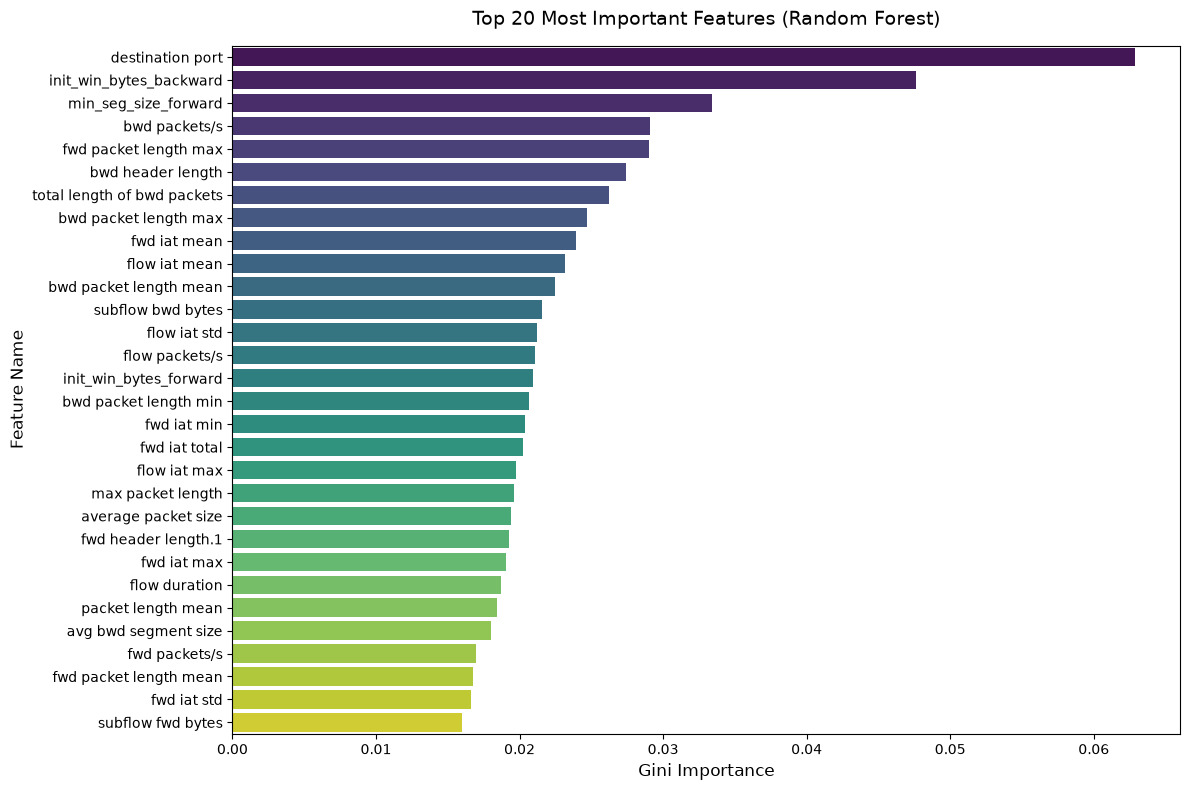


--- Bottom 10 Features (Candidates for Removal) ---
             Feature  Importance
       down/up ratio    0.002689
      syn flag count    0.002656
       fwd psh flags    0.002368
          active max    0.002117
      urg flag count    0.001814
            idle std    0.000630
      fin flag count    0.000348
          active std    0.000282
      rst flag count    0.000000
       bwd urg flags    0.000000
       bwd psh flags    0.000000
       fwd urg flags    0.000000
   bwd avg bulk rate    0.000000
bwd avg packets/bulk    0.000000
  bwd avg bytes/bulk    0.000000
   fwd avg bulk rate    0.000000
fwd avg packets/bulk    0.000000
  fwd avg bytes/bulk    0.000000
      cwe flag count    0.000000
      ece flag count    0.000000


In [39]:
# Sort the features from most to least important
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# Display the Top 20 features
plt.figure(figsize=(12, 8))
sns.barplot(
    x='Importance', 
    y='Feature', 
    data=feature_importance_df.head(30), 
    palette='viridis'
)
plt.title('Top 20 Most Important Features (Random Forest)', fontsize=14, pad=15)
plt.xlabel('Gini Importance', fontsize=12)
plt.ylabel('Feature Name', fontsize=12)
plt.tight_layout()
plt.show()

# Display the Bottom 10 features (the ones you will likely want to drop later)
print("\n--- Bottom 10 Features (Candidates for Removal) ---")
print(feature_importance_df.tail(20).to_string(index=False))

In [40]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import average_precision_score

y_val_pred_smote = rf_model.predict(X_val)
y_val_proba = rf_model.predict_proba(X_val)
classes = rf_model.classes_

val_accuracy = accuracy_score(y_val, y_val_pred_smote)
val_precision = precision_score(
    y_val,
    y_val_pred_smote,
    average="macro",
    zero_division=0
)
val_recall = recall_score(
    y_val,
    y_val_pred_smote,
    average="macro",
    zero_division=0
)
val_f1 = f1_score(
    y_val,
    y_val_pred_smote,
    average="macro",
    zero_division=0
)

# PR-AUC (one-vs-rest)
y_val_bin = label_binarize(y_val, classes=classes)
present = y_val_bin.sum(axis=0) > 0   # only classes present in y_val

val_pr_auc_macro = average_precision_score(
    y_val_bin[:, present], y_val_proba[:, present], average="macro"
)
val_pr_auc_weighted = average_precision_score(
    y_val_bin[:, present], y_val_proba[:, present], average="weighted"
)

print("RF-02 Validation Results")
print("-------------------------")
print(f"Accuracy:            {val_accuracy:.4f}")
print(f"Macro Precision:     {val_precision:.4f}")
print(f"Macro Recall:        {val_recall:.4f}")
print(f"Macro F1:            {val_f1:.4f}")
print(f"Macro PR-AUC:        {val_pr_auc_macro:.4f}")
print(f"Weighted PR-AUC:     {val_pr_auc_weighted:.4f}")

print("\nPer-class PR-AUC")
for i, c in enumerate(classes):
    if present[i]:
        print(f"{c}: {average_precision_score(y_val_bin[:, i], y_val_proba[:, i]):.4f}")

RF-02 Validation Results
-------------------------
Accuracy:            0.9973
Macro Precision:     0.8630
Macro Recall:        0.8528
Macro F1:            0.8571
Macro PR-AUC:        0.8715
Weighted PR-AUC:     0.9978

Per-class PR-AUC
0: 1.0000
1: 1.0000
2: 0.9960
3: 0.9998
4: 0.9948
5: 0.9958
6: 1.0000
7: 1.0000
8: 1.0000
9: 0.9999
10: 1.0000
11: 0.7578
12: 0.0846
13: 0.3721


In [41]:
print(
    classification_report(
        y_val,
        y_val_pred_smote,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

                            precision    recall  f1-score   support

                       Bot       1.00      1.00      1.00       292
                      DDoS       1.00      1.00      1.00     19202
             DoS GoldenEye       0.99      1.00      0.99      1543
                  DoS Hulk       1.00      1.00      1.00     25927
          DoS Slowhttptest       0.99      0.99      0.99       784
             DoS slowloris       0.99      0.99      0.99       808
               FTP-Patator       1.00      1.00      1.00       889
                Heartbleed       1.00      1.00      1.00         2
              Infiltration       1.00      0.83      0.91         6
                  PortScan       1.00      1.00      1.00     13604
               SSH-Patator       1.00      1.00      1.00       483
  Web Attack � Brute Force       0.72      0.69      0.70       220
Web Attack � Sql Injection       0.00      0.00      0.00         3
          Web Attack � XSS       0.39      0.45

In [42]:
y_test_pred_smote = rf_model.predict(X_test)

print("RF-02 Test Results")
print("------------------")

print(
    classification_report(
        y_test,
        y_test_pred_smote,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

RF-02 Test Results
------------------
                            precision    recall  f1-score   support

                       Bot       1.00      1.00      1.00       292
                      DDoS       1.00      1.00      1.00     19203
             DoS GoldenEye       1.00      1.00      1.00      1543
                  DoS Hulk       1.00      1.00      1.00     25927
          DoS Slowhttptest       0.99      0.99      0.99       784
             DoS slowloris       0.99      0.99      0.99       808
               FTP-Patator       1.00      1.00      1.00       890
                Heartbleed       1.00      1.00      1.00         1
              Infiltration       1.00      1.00      1.00         5
                  PortScan       1.00      1.00      1.00     13604
               SSH-Patator       1.00      1.00      1.00       483
  Web Attack � Brute Force       0.77      0.74      0.76       221
Web Attack � Sql Injection       1.00      0.33      0.50         3
         

In [43]:
test_accuracy = accuracy_score(y_test, y_test_pred_smote)

test_macro_precision = precision_score(
    y_test,
    y_test_pred_smote,
    average="macro",
    zero_division=0
)

test_macro_recall = recall_score(
    y_test,
    y_test_pred_smote,
    average="macro",
    zero_division=0
)

test_macro_f1 = f1_score(
    y_test,
    y_test_pred_smote,
    average="macro",
    zero_division=0
)

print(f"Accuracy:        {test_accuracy:.4f}")
print(f"Macro Precision: {test_macro_precision:.4f}")
print(f"Macro Recall:    {test_macro_recall:.4f}")
print(f"Macro F1:        {test_macro_f1:.4f}")

Accuracy:        0.9978
Macro Precision: 0.9441
Macro Recall:    0.8985
Macro F1:        0.9093


In [44]:
# cols_to_drop = [
#     'rst flag count', 'bwd urg flags', 'bwd psh flags', 'fwd urg flags',
#     'bwd avg bulk rate', 'bwd avg packets/bulk', 'bwd avg bytes/bulk',
#     'fwd avg bulk rate', 'fwd avg packets/bulk', 'fwd avg bytes/bulk',
#     'cwe flag count', 'ece flag count'
# ]
# X = X.drop(columns=cols_to_drop)

In [46]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve

from src.resampling import cap_majority_classes, class_count_report
from src.evaluation import print_metrics_report, plot_roc_and_pr, log_experiment
from src.evaluation_multiclass import evaluate_multiclass, plot_confusion_matrix_multiclass

In [47]:

df = load_and_merge_csvs(
    data_dir="../data/CIC2017/",
    output_parquet="../data/raw/merged_raw.parquet"
)

print("Raw shape:", df.shape)

df = clean_dataframe(df)

X_all = df.drop(columns=["label"])
le_all = LabelEncoder()
y_all = le_all.fit_transform(df["label"])
benign_id = list(le_all.classes_).index("BENIGN")

X_train, X_temp, y_train, y_temp = train_test_split(
    X_all, y_all, test_size=0.30, stratify=y_all, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

print(le_all.classes_)
print(np.bincount(y_train))

Loading fast merged raw data from Parquet...
Raw shape: (2830743, 79)
['BENIGN' 'Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'Heartbleed' 'Infiltration' 'PortScan'
 'SSH-Patator' 'Web Attack � Brute Force' 'Web Attack � Sql Injection'
 'Web Attack � XSS']
[1466539    1364   89610    7200  120992    3660    3769    4152       8
      25   63486    2253    1029      15     456]


In [48]:
from sklearn.metrics import f1_score

bot_id = list(le_all.classes_).index("Bot")
attack_ids = [i for i in range(len(le_all.classes_)) if i != benign_id]

def run(cap, cw):
    Xb, yb = cap_majority_classes(X_train, y_train, cap=cap)
    m = RandomForestClassifier(
        n_estimators=300, max_depth=20, max_features="log2",
        min_samples_leaf=2, class_weight=cw, n_jobs=-1, random_state=42,
    ).fit(Xb, yb)
    p = m.predict(X_val)

    ben = y_val == benign_id
    flagged = p != benign_id
    return {
        "cap": cap,
        "class_weight": str(cw),
        "FPR": round((flagged & ben).sum() / ben.sum(), 4),
        "attack_recall": round((flagged & ~ben).sum() / (~ben).sum(), 4),
        "Bot_precision": round(((p == bot_id) & (y_val == bot_id)).sum() / max((p == bot_id).sum(), 1), 3),
        "Bot_recall": round(((p == bot_id) & (y_val == bot_id)).sum() / (y_val == bot_id).sum(), 3),
        "attack_macro_f1": round(f1_score(y_val, p, labels=attack_ids, average="macro", zero_division=0), 4),
    }

results = pd.DataFrame([
    run(50_000,  "balanced_subsample"),
    run(50_000,  None),
    run(200_000, "balanced_subsample"),
    run(200_000, None),
])
display(results)

,cap,class_weight,FPR,attack_recall,Bot_precision,Bot_recall,attack_macro_f1
0,50000,balanced_subsample,0.0089,0.9995,0.131,1.000,0.7813
1,50000,None,0.0021,0.9992,0.660,0.952,0.8030
2,200000,balanced_subsample,0.0068,0.9996,0.149,1.000,0.8030
3,200000,None,0.0014,0.9987,0.677,0.870,0.8022


In [49]:
Xb, yb = cap_majority_classes(X_train, y_train, cap=200_000)
final_rf = RandomForestClassifier(
    n_estimators=300, max_depth=20, max_features="log2",
    min_samples_leaf=2, class_weight=None, n_jobs=-1, random_state=42,
).fit(Xb, yb)

proba_t = final_rf.predict_proba(X_test)
bc = list(final_rf.classes_).index(benign_id)
y_true_t  = (y_test != benign_id).astype(int)
y_pred_t  = (final_rf.predict(X_test) != benign_id).astype(int)
y_score_t = 1 - proba_t[:, bc]

metrics_test = print_metrics_report(y_true_t, y_pred_t, y_score_t, "RF one-model (TEST)")

===== RF one-model (TEST) — Evaluation Report =====
AUC-ROC   : 1.0000
AUC-PR    : 0.9998
Precision : 0.9934
Recall    : 0.9989
F1-score  : 0.9961
FPR       : 0.0014  (1.4 false alarms per 1,000 normal flows)

Classification report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    314259
     Anomaly       0.99      1.00      1.00     63861

    accuracy                           1.00    378120
   macro avg       1.00      1.00      1.00    378120
weighted avg       1.00      1.00      1.00    378120

Confusion matrix:
[[313833    426]
 [    72  63789]]


===== RF one-model (TEST) — Multiclass Evaluation =====
accuracy        : 0.9984
macro_auc_roc   : 0.9998
macro_auc_pr    : 0.8911
macro_precision : 0.9266
macro_recall    : 0.8681
macro_f1        : 0.8682
macro_fpr       : 0.0002
weighted_f1     : 0.9983

Per-class results:
                     class  support  auc_roc  auc_pr  precision  recall  f1_score  false_positives    fpr
                    BENIGN   314259   1.0000  1.0000     0.9998  0.9986    0.9992               72 0.0011
                       Bot      292   0.9998  0.7991     0.6885  0.8630    0.7660              114 0.0003
                      DDoS    19202   1.0000  1.0000     0.9998  0.9997    0.9998                3 0.0000
             DoS GoldenEye     1543   0.9992  0.9985     0.9967  0.9922    0.9945                5 0.0000
                  DoS Hulk    25927   1.0000  1.0000     0.9944  0.9998    0.9971              145 0.0004
          DoS Slowhttptest      784   1.0000  0.9921     0.9617  0.9936    0.9774       

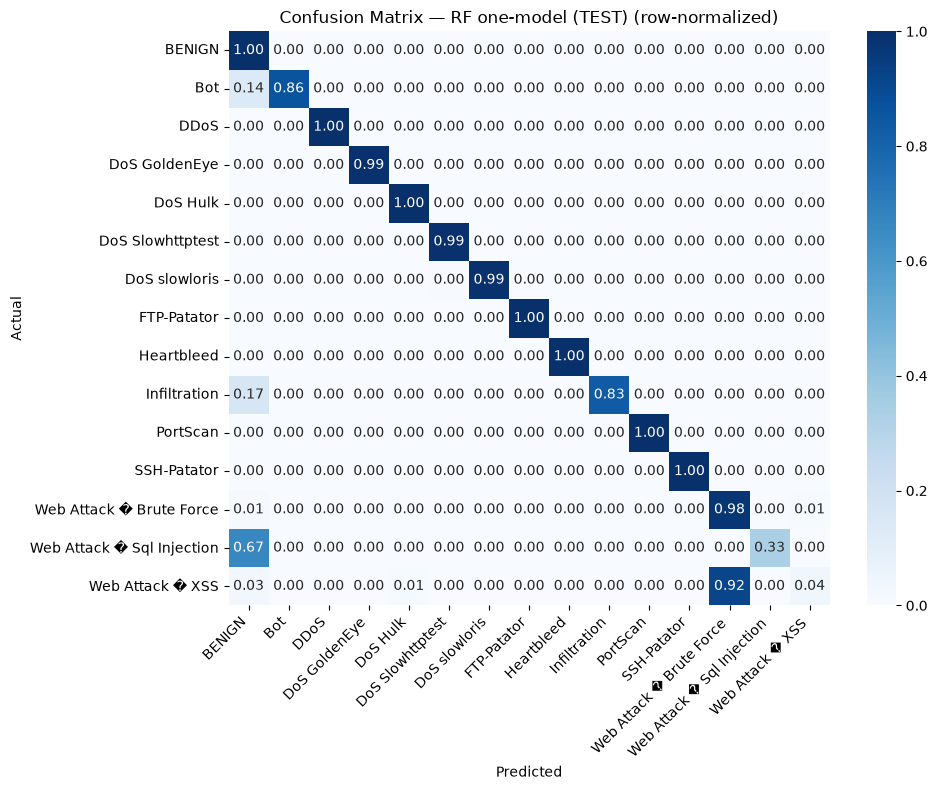

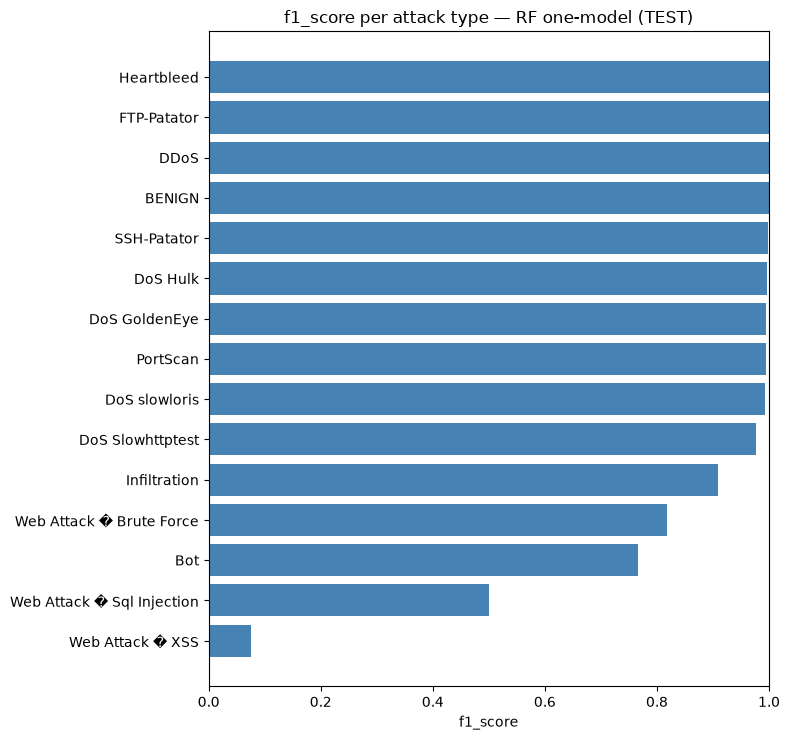


Attack-only averages (TEST):
precision    0.9213
recall       0.8588
f1_score     0.8589
auc_roc      0.9998
auc_pr       0.8833
dtype: float64


,validation,test
precision,0.8367,0.9213
recall,0.8091,0.8588
f1_score,0.8022,0.8589
auc_roc,0.9999,0.9998
auc_pr,0.8769,0.8833



Missed attacks (called BENIGN), by true class:
Bot                           40
DoS Hulk                       5
DDoS                           5
DoS GoldenEye                  4
PortScan                       4
Web Attack � XSS               3
Web Attack � Brute Force       3
Web Attack � Sql Injection     2
DoS Slowhttptest               2
DoS slowloris                  2
SSH-Patator                    1
Infiltration                   1
Name: count, dtype: int64
Logged experiment for RF_one_model_multiclass_TEST -> ../experiments/results_log_one_model.csv


In [50]:
import pandas as pd
from src.evaluation_multiclass import (
    evaluate_multiclass, plot_confusion_matrix_multiclass, plot_per_class_metric)
from src.evaluation import log_experiment

class_names = le_all.inverse_transform(final_rf.classes_)

# ---- TEST: all 15 classes (14 attacks + BENIGN) ----
pred_t  = final_rf.predict(X_test)
proba_t = final_rf.predict_proba(X_test)

summary_test, per_class_test = evaluate_multiclass(
    y_test, pred_t, proba_t, final_rf.classes_, class_names,
    model_name="RF one-model (TEST)")

plot_confusion_matrix_multiclass(
    y_test, pred_t, final_rf.classes_, class_names, "RF one-model (TEST)")
plot_per_class_metric(per_class_test, "f1_score", "RF one-model (TEST)")

# ---- Attack types only (comparable to your teammate's attack-only 0.8942 test macro F1) ----
atk_test = per_class_test[per_class_test["class"] != "BENIGN"]
print("\nAttack-only averages (TEST):")
print(atk_test[["precision", "recall", "f1_score", "auc_roc", "auc_pr"]].mean().round(4))

# ---- Validation vs test, same model ----
summary_val, per_class_val = evaluate_multiclass(
    y_val, final_rf.predict(X_val), final_rf.predict_proba(X_val),
    final_rf.classes_, class_names, verbose=False)
atk_val = per_class_val[per_class_val["class"] != "BENIGN"]

display(pd.DataFrame({
    "validation": atk_val[["precision", "recall", "f1_score", "auc_roc", "auc_pr"]].mean(),
    "test":       atk_test[["precision", "recall", "f1_score", "auc_roc", "auc_pr"]].mean(),
}).round(4))

# ---- Where do missed attacks go? ----
missed = (y_test != benign_id) & (pred_t == benign_id)
print("\nMissed attacks (called BENIGN), by true class:")
print(pd.Series(le_all.inverse_transform(y_test[missed])).value_counts())

# ---- Log it ----
log_experiment("../experiments/results_log_one_model.csv", "RF_one_model_multiclass_TEST",
               params={"n_estimators": 300, "max_depth": 20, "max_features": "log2",
                       "min_samples_leaf": 2, "class_weight": "None", "cap": 200_000},
               metrics=summary_test)

In [52]:
import pandas as pd
from src.evaluation_multiclass import evaluate_multiclass

# Fix the garbled "�" in the web-attack names (an encoding issue in the CSV labels)
class_names = [n.replace("\ufffd", "-") for n in le_all.inverse_transform(final_rf.classes_)]

def per_class_table(X, y, name):
    _, pc = evaluate_multiclass(
        y, final_rf.predict(X), final_rf.predict_proba(X),
        final_rf.classes_, class_names, name, verbose=False)
    return pc.set_index("class")

val  = per_class_table(X_val,  y_val,  "val")
test = per_class_table(X_test, y_test, "test")

pd.set_option("display.max_rows", None)     # never truncate rows
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)

cols = ["support", "precision", "recall", "f1_score", "auc_roc", "auc_pr", "false_positives"]

print(f"Classes in test: {len(test)} | in validation: {len(val)}")

print("\n=== TEST: all classes ===")
display(test[cols].round(4))

print("\n=== VALIDATION: all classes ===")
display(val[cols].round(4))

# One combined table, weakest class (by test F1) first
combined = pd.DataFrame({
    "support_test": test["support"],
    "P_val": val["precision"], "P_test": test["precision"],
    "R_val": val["recall"],    "R_test": test["recall"],
    "F1_val": val["f1_score"], "F1_test": test["f1_score"],
    "AUC-PR_val": val["auc_pr"], "AUC-PR_test": test["auc_pr"],
    "AUC-ROC_test": test["auc_roc"],
}).sort_values("F1_test").round(4)

print("\n=== ALL 15 CLASSES: validation vs test (weakest first) ===")
display(combined)

Classes in test: 15 | in validation: 15

=== TEST: all classes ===


,support,precision,recall,f1_score,auc_roc,auc_pr,false_positives
class,,,,,,,
BENIGN,314259,0.9998,0.9986,0.9992,1.0000,1.0000,72
Bot,292,0.6885,0.8630,0.7660,0.9998,0.7991,114
DDoS,19202,0.9998,0.9997,0.9998,1.0000,1.0000,3
DoS GoldenEye,1543,0.9967,0.9922,0.9945,0.9992,0.9985,5
DoS Hulk,25927,0.9944,0.9998,0.9971,1.0000,1.0000,145
DoS Slowhttptest,784,0.9617,0.9936,0.9774,1.0000,0.9921,31
DoS slowloris,808,0.9938,0.9926,0.9932,0.9989,0.9973,5
FTP-Patator,890,1.0000,1.0000,1.0000,1.0000,1.0000,0
Heartbleed,1,1.0000,1.0000,1.0000,1.0000,1.0000,0



=== VALIDATION: all classes ===


,support,precision,recall,f1_score,auc_roc,auc_pr,false_positives
class,,,,,,,
BENIGN,314259,0.9997,0.9986,0.9992,0.9999,1.0000,82
Bot,292,0.6773,0.8699,0.7616,0.9998,0.8034,121
DDoS,19202,0.9996,0.9999,0.9998,1.0000,1.0000,7
DoS GoldenEye,1543,0.9929,0.9922,0.9925,1.0000,0.9992,11
DoS Hulk,25927,0.9944,0.9996,0.9970,1.0000,1.0000,147
DoS Slowhttptest,784,0.9714,0.9962,0.9836,1.0000,0.9968,23
DoS slowloris,808,0.9963,0.9889,0.9925,0.9999,0.9952,3
FTP-Patator,889,1.0000,0.9944,0.9972,0.9994,0.9988,0
Heartbleed,2,1.0000,0.5000,0.6667,1.0000,1.0000,0



=== ALL 15 CLASSES: validation vs test (weakest first) ===


,support_test,P_val,P_test,R_val,R_test,F1_val,F1_test,AUC-PR_val,AUC-PR_test,AUC-ROC_test
class,,,,,,,,,,
Web Attack - XSS,98,0.4000,0.5714,0.0204,0.0408,0.0388,0.0762,0.4430,0.4602,0.9998
Web Attack - Sql Injection,3,0.0000,1.0000,0.0000,0.3333,0.0000,0.5000,0.2108,0.3773,0.9999
Bot,292,0.6773,0.6885,0.8699,0.8630,0.7616,0.7660,0.8034,0.7991,0.9998
Web Attack - Brute Force,220,0.6935,0.7026,0.9729,0.9773,0.8098,0.8175,0.8329,0.8197,0.9999
Infiltration,6,1.0000,1.0000,1.0000,0.8333,1.0000,0.9091,1.0000,0.9242,1.0000
DoS Slowhttptest,784,0.9714,0.9617,0.9962,0.9936,0.9836,0.9774,0.9968,0.9921,1.0000
DoS slowloris,808,0.9963,0.9938,0.9889,0.9926,0.9925,0.9932,0.9952,0.9973,0.9989
PortScan,13604,0.9889,0.9895,0.9996,0.9993,0.9942,0.9944,0.9976,0.9980,0.9999
DoS GoldenEye,1543,0.9929,0.9967,0.9922,0.9922,0.9925,0.9945,0.9992,0.9985,0.9992


In [56]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

pred = final_rf.predict(X_test)
classes = final_rf.classes_
names = [n.replace("\ufffd", "-") for n in le_all.inverse_transform(classes)]

# Rows = actual class, columns = predicted class
cm = confusion_matrix(y_test, pred, labels=classes)

tp = np.diag(cm)                    # correct predictions per class
predicted = cm.sum(axis=0)          # everything the model labeled as this class
fp = predicted - tp                 # wrong predictions into this class
precision = np.divide(tp, predicted, out=np.zeros(len(tp)), where=predicted > 0)

prec_table = pd.DataFrame({
    "Precision": precision.round(4),
    "Correct (TP)": tp,
    "Wrong (FP)": fp,
    "Total predicted": predicted,
}, index=names)

pd.set_option("display.max_rows", None)
display(prec_table)

is_benign = classes == benign_id
print("Macro precision, 14 attacks:", round(precision[~is_benign].mean(), 4))
print("Macro precision, all 15:    ", round(precision.mean(), 4))



,Precision,Correct (TP),Wrong (FP),Total predicted
BENIGN,0.9998,313833,72,313905
Bot,0.6885,252,114,366
DDoS,0.9998,19196,3,19199
DoS GoldenEye,0.9967,1531,5,1536
DoS Hulk,0.9944,25922,145,26067
DoS Slowhttptest,0.9617,779,31,810
DoS slowloris,0.9938,802,5,807
FTP-Patator,1.0000,890,0,890
Heartbleed,1.0000,1,0,1
Infiltration,1.0000,5,0,5


Macro precision, 14 attacks: 0.9213
Macro precision, all 15:     0.9266


In [57]:
cm_df = pd.DataFrame(cm, index=names, columns=names)   # actual (rows) vs predicted (columns)
row = cm_df.loc["Web Attack - XSS"]
print(row[row > 0])

BENIGN                       3
DoS Hulk                     1
Web Attack - Brute Force    90
Web Attack - XSS             4
Name: Web Attack - XSS, dtype: int64
